In [ ]:
## Image Classification

In [2]:
import os
import numpy as np
import keras
from keras import layers
from tensorflow import data as tf_data
import matplotlib.pyplot as plt

In [1]:
!curl -O https://download.microsoft.com/download/3/E/1/3E1C3F21-ECDB-4869-8368-6DEBA77B919F/kagglecatsanddogs_5340.zip

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100  786M  100  786M    0     0   130M      0  0:00:06  0:00:06 --:--:--  121M


In [3]:
!unzip -q 'kagglecatsanddogs_5340.zip' # -q flag is metadata?

In [4]:
!ls

 CDLA-Permissive-2.0.pdf      PetImages        sample_data
 kagglecatsanddogs_5340.zip  'readme[1].txt'


In [5]:
!ls PetImages

Cat  Dog


In [6]:
# delete ~ 100 images from each class.

In [7]:
# Can be run only once because we are DELETING
num_skipped=0

for folder_name in ("Cat", "Dog"):
  max_images=100
  folder_path=os.path.join("PetImages", folder_name)

  for image_i, fname in enumerate(os.listdir(folder_path)):
    fpath=os.path.join(folder_path, fname)

    try:
      fobj=open(fpath, 'rb')
      is_jfif=b"JFIF" in fobj.peek(10)
    finally:
      fobj.close()
    if image_i > max_images or not is_jfif:
      num_skipped+=1
      os.remove(fpath) # delete a corrupt image file.
print(f"Deleted {num_skipped} images.")


Deleted 24814 images.


In [8]:
!ls PetImages/Cat/

10058.jpg  11444.jpg  1231.jpg	2803.jpg  4057.jpg  6511.jpg  9040.jpg
10258.jpg  11477.jpg  1273.jpg	2832.jpg  412.jpg   6733.jpg  9326.jpg
10454.jpg  11532.jpg  1324.jpg	2891.jpg  4289.jpg  6908.jpg  9397.jpg
10514.jpg  11580.jpg  149.jpg	2968.jpg  4563.jpg  7082.jpg  9487.jpg
10536.jpg  11589.jpg  1593.jpg	3037.jpg  4672.jpg  7100.jpg  9612.jpg
10545.jpg  11654.jpg  1709.jpg	3047.jpg  4869.jpg  7365.jpg  9648.jpg
1060.jpg   11719.jpg  1742.jpg	3101.jpg  488.jpg   7366.jpg  9687.jpg
10813.jpg  11768.jpg  2016.jpg	3115.jpg  4924.jpg  7518.jpg  9723.jpg
10834.jpg  11838.jpg  2201.jpg	3368.jpg  5160.jpg  7688.jpg  9842.jpg
11121.jpg  11887.jpg  2323.jpg	3751.jpg  5317.jpg  8659.jpg  9850.jpg
11147.jpg  1199.jpg   247.jpg	3810.jpg  5323.jpg  8715.jpg  9889.jpg
11248.jpg  12011.jpg  2504.jpg	3909.jpg  5738.jpg  8858.jpg  9892.jpg
11263.jpg  120.jpg    2556.jpg	4013.jpg  626.jpg   8887.jpg  9964.jpg
11354.jpg  12211.jpg  2674.jpg	404.jpg   6352.jpg  8903.jpg


In [9]:
image_size=(224,224) # how many pixels for each image
batch_size=10

train_ds, val_ds = keras.utils.image_dataset_from_directory( # use keras and read from the directory
    "PetImages",
    validation_split=0.2, # take 20% for our testing set.
    subset="both", # for both Cat and Dog.
    seed=420, # like Minecraft seeds
    image_size=image_size, # pixels.
    batch_size=batch_size
)

Found 188 files belonging to 2 classes.
Using 151 files for training.
Using 37 files for validation.


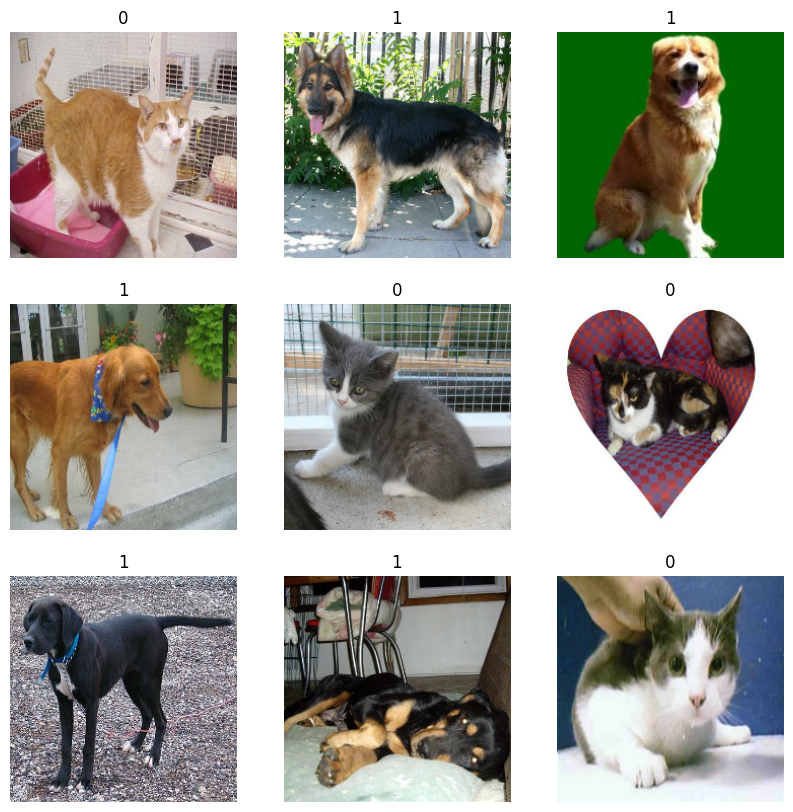

In [10]:
plt.figure(figsize=(10,10))
for images, labels in train_ds.take(1): # take a random image from the training sample.
  for i in range(9): # we want a 3x3 picture.
    ax=plt.subplot(3, 3, i+1)
    plt.imshow(np.array(images[i]).astype('uint8')) # params for showing an image via matplotlib
    plt.title(int(labels[i]))
    plt.axis('off')

In [11]:
# Deep Learning Model, add each feature.

In [12]:
data_augmentation_layers=[
    layers.RandomFlip('horizontal'),
    layers.RandomRotation(0.1), # rotate 10% or 10 degrees.
]

def data_augmentation(images):
  for layer in data_augmentation_layers:
    images=layer(images) # flips the image.
  return images




In [13]:
# Train the machine to notice slight angle differences.

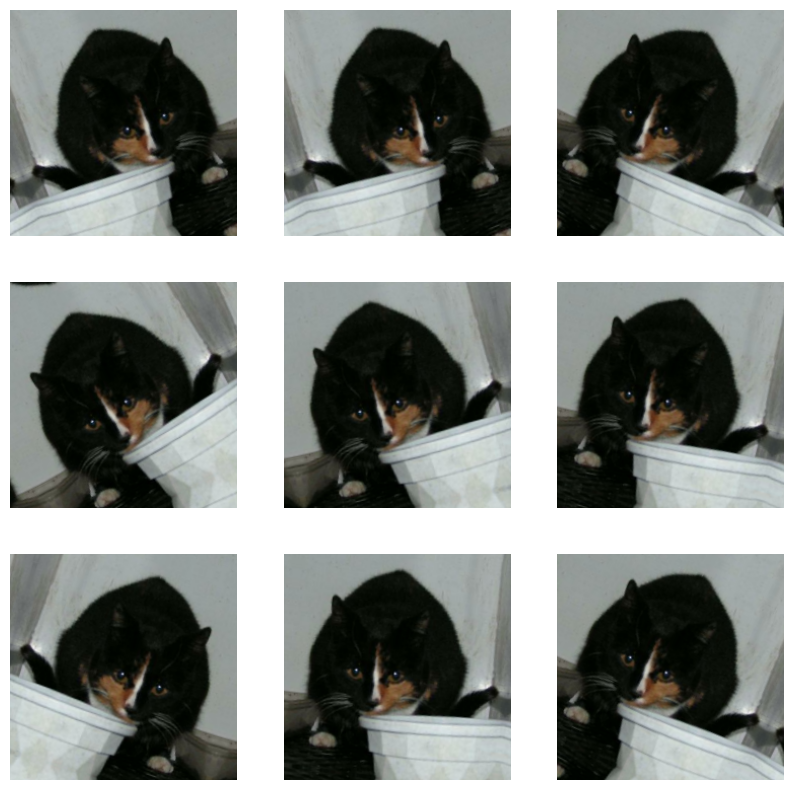

In [14]:
plt.figure(figsize=(10,10))
for images, _ in train_ds.take(1): # The underscore means to select from an index.
  for i in range(9): # still want a 3x3 grid.
    augmented_images=data_augmentation(images)
    ax=plt.subplot(3,3,i+1)
    plt.imshow(np.array(augmented_images[0]).astype('uint8')) # params for showing an image via matplot
    plt.axis('off')


In [15]:
# Apply data_augmentation to the training images.
train_ds = train_ds.map(
    lambda img, label: (data_augmentation(img), label)
)

train_ds = train_ds.prefetch(tf_data.AUTOTUNE) # prefetch uses GPU memory to improve performance.
val_ds=val_ds.prefetch(tf_data.AUTOTUNE)

In [16]:
# Create the model now.
def make_model(input_shape, num_classes): # need a shape, and num of classes
  inputs=keras.Input(shape=input_shape) # use keras function for inputs.

  # Define each layer for the deep learning
  #### Entry Block #######
  x=layers.Rescaling(1.0/255)(inputs) # define exactly what function we want to use for each layer.
  x=layers.Conv2D(
      128,
      3,
      strides=2,
      padding='same'
      )(x) # is the result from the first layer
  x=layers.BatchNormalization()(x) # normalize the last layer.
  x=layers.Activation('relu')(x)

  previous_block_activation = x # set aside residual.

  ###### Looping for three different sizes #########
  for size in [256, 512, 728]:
    x=layers.Activation('relu')(x)
    x=layers.SeparableConv2D(size, 3, padding='same')(x)
    x=layers.BatchNormalization()(x)

    x=layers.Activation('relu')(x)
    x=layers.SeparableConv2D(size, 3, padding='same')(x)
    x=layers.BatchNormalization()(x)
    x=layers.MaxPooling2D(3, strides=2, padding='same')(x)

    ### Project Residual ###
    residual = layers.Conv2D(size, 1, strides=2, padding='same')(previous_block_activation)

    x=layers.add([x, residual]) # add back residual
    previous_block_activation=x # set aside for next residual

  x=layers.SeparableConv2D(1024, 3, padding='same')(x)
  x=layers.BatchNormalization()(x)
  x=layers.Activation('relu')(x)

  x=layers.GlobalAveragePooling2D()(x)
  if num_classes == 2:
    units=1
  else:
    units=num_classes

  x=layers.Dropout(0.25)(x)

  outputs=layers.Dense(units, activation=None)(x) # we specify activation to None so we can return logits.

  return keras.Model(inputs, outputs)

model=make_model(input_shape=image_size+(3,), num_classes=2)

In [17]:
epochs=8 # like bins

# callbacks does training
# Model checkpoint automatically saves the model after each epoch.
callbacks=[
    keras.callbacks.ModelCheckpoint('save_at_{epoch}.keras'),
]

# optmizer / tolerance. Adam is used.
# logits =  True or False.
# metrics is our output.
model.compile(
  optimizer=keras.optimizers.Adam(1e-3),
  loss=keras.losses.BinaryCrossentropy(from_logits=True),
  metrics=[keras.metrics.BinaryAccuracy()],
)

# model statement
history=model.fit(
    train_ds,
    epochs=epochs,
    callbacks=callbacks,
    validation_data=val_ds
)

# binary accuracy - train data
# val_binary - test data

Epoch 1/8
16/16 ━━━━━━━━━━━━━━━━━━━━ 190s 11s/step - binary_accuracy: 0.5298 - loss: 0.9242 - val_binary_accuracy: 0.4595 - val_loss: 0.6940
Epoch 2/8
16/16 ━━━━━━━━━━━━━━━━━━━━ 156s 10s/step - binary_accuracy: 0.5695 - loss: 0.7113 - val_binary_accuracy: 0.4595 - val_loss: 0.6953
Epoch 3/8
16/16 ━━━━━━━━━━━━━━━━━━━━ 199s 10s/step - binary_accuracy: 0.6490 - loss: 0.6246 - val_binary_accuracy: 0.4595 - val_loss: 0.6949
Epoch 4/8
16/16 ━━━━━━━━━━━━━━━━━━━━ 198s 9s/step - binary_accuracy: 0.6026 - loss: 0.6859 - val_binary_accuracy: 0.4595 - val_loss: 0.7022
Epoch 5/8
16/16 ━━━━━━━━━━━━━━━━━━━━ 201s 9s/step - binary_accuracy: 0.5629 - loss: 0.6664 - val_binary_accuracy: 0.4595 - val_loss: 0.7004
Epoch 6/8
16/16 ━━━━━━━━━━━━━━━━━━━━ 149s 9s/step - binary_accuracy: 0.6689 - loss: 0.5960 - val_binary_accuracy: 0.4595 - val_loss: 0.7062
Epoch 7/8
16/16 ━━━━━━━━━━━━━━━━━━━━ 146s 9s/step - binary_accuracy: 0.5762 - loss: 0.6848 - val_binary_accuracy: 0.4595 - val_loss: 0.7134
Epoch 8/8
16/16 ━

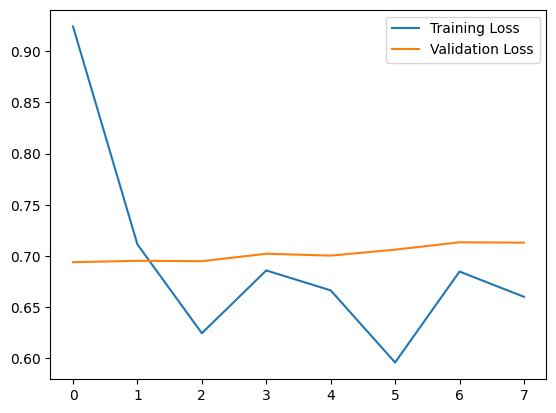

Training Loss: 
Validation Loss: 


In [18]:
# is the range of epochs
plt.plot(range(len(history.history['loss'])), history.history['loss'], label='Training Loss')
plt.plot(range(len(history.history['val_loss'])), history.history['val_loss'], label='Validation Loss')
plt.legend()
plt.show()
print("Training Loss: ")
print("Validation Loss: ")

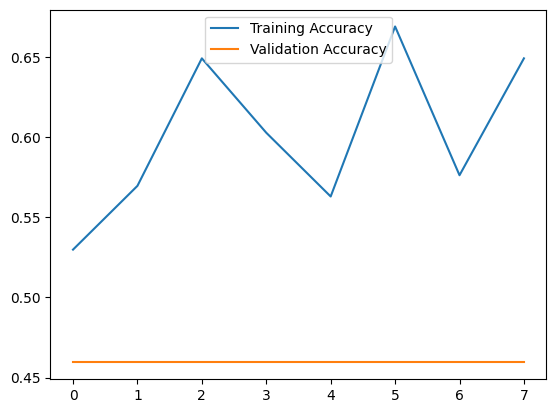

Training Acc: 
Validation Acc: 


In [19]:
plt.plot(range(len(history.history['binary_accuracy'])), history.history['binary_accuracy'], label='Training Accuracy')
plt.plot(range(len(history.history['val_binary_accuracy'])), history.history['val_binary_accuracy'], label='Validation Accuracy')
plt.legend()
plt.show()
print("Training Acc: ")
print("Validation Acc: ")

In [20]:
# We want loss to be down, and accuracy to be up

In [21]:
# Transfer Learning
def make_transfer_model(input_shape, num_classes):
  backbone=keras.applications.MobileNetV2(
      weights='imagenet',
      include_top=False,
      input_shape=input_shape
  )
  backbone.trainable=False # avoids overfitting only on small datasets..

  inputs=layers.Input(input_shape)

  # Still need to define layers for the learning model.
  x=keras.applications.mobilenet_v2.preprocess_input(inputs) # Skews function from -1,1
  x=backbone(x)
  x=layers.Dropout(0.3)(x) # randomly drop 30% of training data (instructor called them "neurons") to prevent overfitting.
  x=layers.GlobalAveragePooling2D()(x) # Use 2D because we have image data.

  if num_classes==2:
    units=1
  else:
    units=num_classes

  x=layers.Dropout(0.25)(x) # drop again to reduce overfitting.

  outputs=layers.Dense(units, activation=None)(x) # Model output
  return keras.Model(inputs,outputs, name='Keypoint_detector')




In [22]:
model2=make_transfer_model(input_shape=image_size+(3,), num_classes=2)

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [23]:
# In this block, editing the natural log makes the epochs run faster.
epochs=4 # like bins

# callbacks does training
# Model checkpoint automatically saves the model after each epoch.
callbacks=[
    keras.callbacks.ModelCheckpoint('save_at_{epoch}.keras'),
]

# optmizer / tolerance. Adam.
# logits =  True or False.
# metrics is our output.
model.compile(
  optimizer=keras.optimizers.Adam(3e-4),
  loss=keras.losses.BinaryCrossentropy(from_logits=True),
  metrics=[keras.metrics.BinaryAccuracy(name="acc")],
)

# model statement
history=model.fit(
    train_ds,
    epochs=epochs,
    callbacks=callbacks,
    validation_data=val_ds
)

# binary accuracy - train data
# val_binary - test data

Epoch 1/4
16/16 ━━━━━━━━━━━━━━━━━━━━ 172s 10s/step - acc: 0.6755 - loss: 0.6356 - val_acc: 0.4595 - val_loss: 0.7153
Epoch 2/4
16/16 ━━━━━━━━━━━━━━━━━━━━ 150s 9s/step - acc: 0.6755 - loss: 0.5533 - val_acc: 0.4595 - val_loss: 0.7130
Epoch 3/4
16/16 ━━━━━━━━━━━━━━━━━━━━ 153s 10s/step - acc: 0.7152 - loss: 0.5125 - val_acc: 0.4595 - val_loss: 0.7074
Epoch 4/4
16/16 ━━━━━━━━━━━━━━━━━━━━ 150s 9s/step - acc: 0.6424 - loss: 0.6220 - val_acc: 0.4595 - val_loss: 0.7146


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 353ms/step
This image is 55.53% cat and 44.47% dog.


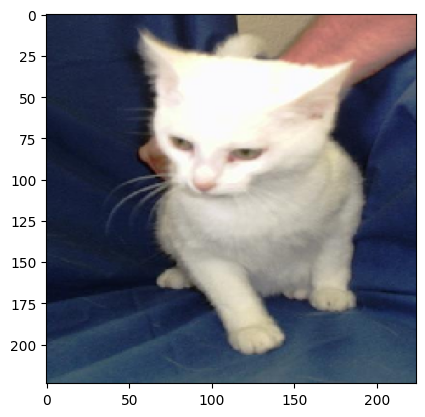

In [33]:
img = keras.utils.load_img("PetImages/Cat/11121.jpg", target_size=image_size)
plt.imshow(img)

img_array = keras.utils.img_to_array(img)
img_array = keras.ops.expand_dims(img_array, 0)  # Create batch axis

predictions = model.predict(img_array)
score = float(keras.ops.sigmoid(predictions[0][0]))
print(f"This image is {100 * (1 - score):.2f}% cat and {100 * score:.2f}% dog.")